# FoldFlux: an AI second opinion on uncertain BRCA1 mutations

When a genetic test reports a "variant of uncertain significance" (VUS) — a single-letter change in a protein that nobody can yet call harmful or harmless — a genetic counselor sitting with a patient often has only computer predictions to lean on, because most human genes have no experimental lab map. **FoldFlux** asks how far a free, sequence-only protein language model (`facebook/esm2_t33_650M_UR50D`) can be trusted on `1,837` lab-tested single-letter changes across `326` positions of the `1,863`-letter BRCA1 protein, how it compares against simple baselines when tuned on one domain (`positions 1–101`) and tested once on a held-out domain (`positions 1631–1855`), and where it goes blind.

*This project is a prototype and is not medical advice.*

**BRCA1 is the exam, not the use case.** At the positions we test, a 2018 CRISPR saturation genome editing study (Findlay et al., *Nature*) already measured 96.5% of all possible single-letter DNA changes in living human cells, so a genetic counselor would use the lab result at those positions rather than our tool. We use BRCA1 because it is one of the few genes with a lab answer key, letting us grade the model in the open to learn what to expect on genes that have no lab map.

**What is already known:**
- **ProteinGym** (Notin et al.) already benchmarks `facebook/esm2_t33_650M_UR50D` and other protein language models zero-shot on this exact Findlay et al. (2018) BRCA1 substitution table.
- **Evo 2 BRCA1 notebook** (Arc Institute, also published by NVIDIA) runs a zero-shot DNA language model on the same study's `3,893` single-nucleotide changes.
- **AlphaMissense** (Cheng et al.) is a stronger variant predictor that combines evolutionary and structural signals, and as far as we know its predictions are free to download; we do not claim to be better or cheaper.

In [1]:
import importlib.util
import os
import sys

REPO_URL = "https://github.com/godtier812/veritashackathon"
if (
    importlib.util.find_spec("google") is not None
    and importlib.util.find_spec("google.colab") is not None
    and not os.path.exists("src/config.py")
):
    get_ipython().system(f"git clone --depth 1 {REPO_URL} repo")
    get_ipython().run_line_magic("cd", "repo")
    get_ipython().system("pip install -q biopython==1.88")

if "." not in sys.path:
    sys.path.insert(0, ".")

from src import config, load

## The data in plain words

Our input dataset (`data/brca1_missense_scores_slim.csv`, verified against the raw ProteinGym file `data/BRCA1_HUMAN_Findlay_2018.csv` and the `1,863`-letter wild-type FASTA `data/BRCA1_HUMAN_Findlay_2018_wildtype.fasta`) contains `1,837` lab-tested single-amino-acid substitutions across `326` distinct positions in two separate regions of BRCA1:
- **`start` region (`START_REGION = (1, 101)`):** the RING domain, covering `101` positions (`1–101`) with `575` lab-tested mutations. Used exclusively for tuning cutoffs and fitting Arm 3.
- **`end` region (`END_REGION = (1631, 1855)`):** the BRCT domain, covering `225` positions (`1631–1855`) with `1,262` lab-tested mutations. Held out for the single test run.

Each mutation's experimental function score is mapped to one of three classes using the study's cutoffs (`LOF_BELOW = -1.328`, `FUNC_ABOVE = -0.748`):
- **`LOF` (harmful):** loss of function (`function_score < -1.328`).
- **`FUNC` (harmless):** functional (`function_score > -0.748`).
- **`INT` (intermediate, excluded from tuning and headline):** `-1.328 <= function_score <= -0.748` (`155` rows total: `59` in `start`, `96` in `end`), reported separately in `outputs/results/int_rows.csv`.

| Region | Positions | `LOF` (harmful) | `INT` (intermediate) | `FUNC` (harmless) | Binary (`LOF` + `FUNC`) | Total lab-tested |
| --- | --- | ---: | ---: | ---: | ---: | ---: |
| `start` (tuning) | `1–101` (`101`) | `131` | `59` | `385` | `516` | `575` |
| `end` (held-out test) | `1631–1855` (`225`) | `267` | `96` | `899` | `1,166` | `1,262` |
| **Total** | **`326` positions** | **`398`** | **`155`** | **`1,284`** | **`1,682`** | **`1,837`** |

In [2]:
import pandas as pd

load.check_inputs()
counts = load.class_counts()
counts_table = pd.DataFrame.from_dict(counts, orient="index")
counts_table.index.name = "region"
counts_table["total"] = counts_table.sum(axis=1)
print("\nClass counts by region:")
print(counts_table.to_string())

Check 1/6 passed: SHA-256 hashes match for raw CSV, slim CSV, and FASTA.
Check 2/6 passed: slim CSV has 1837 rows, 8 columns, no nulls, unique mutants.
Check 3/6 passed: all 1837 rows match mutant parsing, region, class, and wild-type sequence.
Check 4/6 passed: class counts match expected counts.
Check 5/6 passed: 326 distinct positions found.
Check 6/6 passed: no function_score equals -1.328 or -0.748.

Class counts by region:
        LOF  INT  FUNC  total
region                       
start   131   59   385    575
end     267   96   899   1262


## How ESM-2 zero-shot scoring works

ESM-2 (`facebook/esm2_t33_650M_UR50D`) is a masked language model trained only on natural protein sequences by hiding individual amino-acid letters and predicting the missing letter from the surrounding sequence context. Because BRCA1 has `1,863` amino acids, we slice two `500`-letter windows (`window A` covering positions `1–500` for the `start` region, and `window B` covering positions `1364–1863` for the `end` region) and mask one position at a time with `<mask>`. From that single masked forward pass, we take the model's log-probabilities across the `20` standard amino acids at the masked token index and score each of the `19` possible single-letter swaps as `esm_score = log P(new_letter) - log P(wild_type)`. A negative `esm_score` means the model finds the new letter less likely than the wild-type letter at that position, while the position's Shannon entropy (in nats, from `0` to `ln(20) ≈ 2.996`) measures how uncertain the model is across the `20` letters.

**Worked examples of the window and token index maths (`502` tokens per window: `<cls>` at index `0`, `500` amino-acid tokens at indices `1–500`, `<eos>` at index `501`):**
- **Start-region example (`C61`, position `61`):**
  - `window A` slices residues `1–500` (`seq[0:500]`).
  - Because the start token `<cls>` occupies token index `0`, protein position `61` maps to `token_index = 61 - 1 + 1 = 61` (`position 61 -> token index 61`).
  - At token index `61`, the unmasked token is `C` (`token_at_index == wild_type == "C"`); for `C61G`, `esm_score = -10.499830` and `entropy = 0.005092`.
- **End-region example (`M1775`, position `1775`):**
  - `window B` slices residues `1364–1863` (`seq[1363:1863]`).
  - With `<cls>` at token index `0`, residue `1775` maps to `token_index = 1775 - 1364 + 1 = 1775 - 1363 = 412` (`1775 -> window B 1364–1863 -> token index 1775 - 1363 = 412`).
  - At token index `412`, the unmasked token is `M` (`token_at_index == wild_type == "M"`).

In [3]:
from src import esm_score

RECOMPUTE_SCORES = False

if RECOMPUTE_SCORES:
    device = esm_score.choose_device(allow_cpu=False)
    seq = load.load_wild_type()
    positions = esm_score.scored_positions()
    tokenizer, model = esm_score.load_model(config.MODEL_ID, device)
    scores = esm_score.score_positions(
        model,
        tokenizer,
        seq,
        positions,
        device,
        batch_size=config.ESM_BATCH_SIZE,
    )
    print(f"Scored in memory only (no file written): {len(scores)} rows")
else:
    scores = load.load_scores()
    unique_models = scores["model_id"].unique().tolist()
    print(f"Loaded cached scores: {len(scores)} rows, unique model_id={unique_models}")

pos61_swaps = scores.loc[scores["position"] == 61].reset_index(drop=True)
assert len(pos61_swaps) == 19
print(f"\nAll {len(pos61_swaps)} scored swaps at position 61:")
print(
    pos61_swaps[
        [
            "mutant",
            "position",
            "wild_type",
            "new_letter",
            "window",
            "token_index",
            "token_at_index",
            "esm_score",
            "entropy",
            "is_lab_tested",
        ]
    ].to_string(index=False)
)

Loaded cached scores: 6194 rows, unique model_id=['facebook/esm2_t33_650M_UR50D']

All 19 scored swaps at position 61:
mutant  position wild_type new_letter window  token_index token_at_index  esm_score  entropy  is_lab_tested
  C61A        61         C          A      A           61              C -14.507460 0.005092              0
  C61D        61         C          D      A           61              C -13.249800 0.005092              0
  C61E        61         C          E      A           61              C -14.314805 0.005092              0
  C61F        61         C          F      A           61              C  -9.539024 0.005092              1
  C61G        61         C          G      A           61              C -10.499830 0.005092              1
  C61H        61         C          H      A           61              C -12.922159 0.005092              0
  C61I        61         C          I      A           61              C -14.403553 0.005092              0
  C61K        61 

## The four arms and the cutoff rule

Every arm assigns each mutation a `harm_score` where higher values mean more likely harmful (`LOF`):
- **`arm0` (`Always harmless`):** Always predicts harmless (`cutoff = None`, constant harm score `0.0`, flags `0` mutations).
- **`arm1` (`BLOSUM62 rule`):** Negated 1992 BLOSUM62 substitution score from Biopython (`harm_arm1 = 0.0 - blosum62(wild_type, new_letter)`).
- **`arm2` (`ESM-2 zero-shot`):** Negated zero-shot ESM-2 log-odds score (`harm_arm2 = 0.0 - esm_score`).
- **`arm3` (`Logistic regression on ESM-2 + BLOSUM62 + chemistry`):** Standardised logistic regression (`StandardScaler` + `LogisticRegression(C=1.0, solver="lbfgs", max_iter=100, random_state=42)`) fit on the `516` start-region `LOF` and `FUNC` rows (`59` `INT` rows excluded) over `8` features (`esm_score`, `blosum_score`, `entropy`, `size_change`, `hydrophobicity_change`, `to_proline`, `from_cysteine`, `from_glycine`). Its harm score is the predicted probability of `LOF`.

**The `90%`-catch inclusive (`>=`) highest-cutoff rule:**
- A mutation is flagged when `harm_score >= cutoff`.
- On the `start` region (`131` `LOF` harmful and `385` `FUNC` harmless rows), we sort the `131` harmful scores from highest to lowest, compute the required count via integer arithmetic `needed = -(-(90 * 131) // 100) = 118`, and choose the `118`th highest harmful score as the cutoff.
- This gives the **highest** observed score that still flags at least `90%` of harmful mutations. Because flagging uses `>=`, mutations with tied harm scores always receive the same call.
- For `arm3`, the cutoff is chosen on out-of-fold probabilities from `5`-fold cross-validation grouped by `position` (`out-of-fold probabilities, StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42), groups = position`) before refitting the pipeline once on all `516` start-region `LOF` and `FUNC` rows.
- For the demo's **"Can't tell" band** (`arm2` only, set on the `start` region): `cutoff_a` is `arm2`'s `90%`-catch cutoff, and `cutoff_b` is the lowest observed harm score that flags at most `10%` of the `385` start-region `FUNC` rows (at most `38` rows).

**Worked example (`BUILD_SPEC.md` Section 8.3, `6` rows with `3` harmful and `3` harmless):**

| Row | Harm score | Harmful? |
| --- | ---: | --- |
| `a` | `0.9` | `yes` |
| `b` | `0.7` | `no` |
| `c` | `0.5` | `yes` |
| `d` | `0.5` | `no` |
| `e` | `0.5` | `yes` |
| `f` | `0.1` | `no` |

- Harmful scores sorted high to low: `0.9, 0.5, 0.5` (`n = 3`).
- **Target `90%`:** `needed = 3` -> cutoff = `0.5` -> flags `a, b, c, d, e` (caught `3` of `3`, false alarms `2` of `3` because row `d` ties with `c` and `e` at `0.5`).
- **Target `60%`:** `needed = 2` -> cutoff = `0.5` again -> catch rate reached is `100.0%` (`3` of `3`), because the tie at `0.5` is not split.
- **Target `30%`:** `needed = 1` -> cutoff = `0.9` -> flags `a` only (caught `1` of `3`, false alarms `0` of `3`).

In [4]:
import json

with open(config.FROZEN_PATH, "r", encoding="utf-8") as handle:
    frozen = json.load(handle)

n_harm_start = int(frozen["tuning_counts"]["harmful"])
n_func_start = int(frozen["tuning_counts"]["harmless"])
n_int_start = int(frozen["tuning_counts"]["int_excluded"])
n_binary_start = n_harm_start + n_func_start

print(f"Tuning region: {frozen['tuning_region']} | Test region: {frozen['test_region']}")
print(
    f"Start-region tuning counts: LOF={n_harm_start}, FUNC={n_func_start} "
    f"(binary total={n_binary_start}), INT excluded={n_int_start}"
)

for arm_key in ("arm0", "arm1", "arm2", "arm3"):
    arm_cfg = frozen["arms"][arm_key]
    cutoff_val = arm_cfg["cutoff"]
    if cutoff_val is None:
        print(f"\n{arm_key} ({arm_cfg['name']}): cutoff=None (flags 0 rows)")
        continue
    caught = int(arm_cfg["tuning_caught"])
    fa = int(arm_cfg["tuning_false_alarms"])
    flagged = caught + fa
    flagged_pct = 100.0 * flagged / n_binary_start
    print(
        f"\n{arm_key} ({arm_cfg['name']}): cutoff={cutoff_val:.6f} | "
        f"start caught={caught}/{n_harm_start} ({100.0 * caught / n_harm_start:.1f}%) | "
        f"start false alarms={fa}/{n_func_start} ({100.0 * fa / n_func_start:.1f}%) | "
        f"start flagged={flagged}/{n_binary_start} ({flagged_pct:.1f}%)"
    )
    if arm_key == "arm1":
        print(
            f"  Arm 1 integer-tie share of start-region LOF/FUNC rows flagged: "
            f"{flagged} of {n_binary_start} ({flagged_pct:.1f}%)"
        )
    if arm_key == "arm3":
        oof_caught = int(arm_cfg["out_of_fold_caught"])
        oof_fa = int(arm_cfg["out_of_fold_false_alarms"])
        print(
            f"  Arm 3 out-of-fold caught={oof_caught}/{n_harm_start} "
            f"({100.0 * oof_caught / n_harm_start:.1f}%), "
            f"out-of-fold false alarms={oof_fa}/{n_func_start} "
            f"({100.0 * oof_fa / n_func_start:.1f}%), "
            f"converged={arm_cfg['converged']}"
        )

band_cfg = frozen["band"]
print(
    f"\nArm 2 'Can\'t tell' band: has_band={band_cfg['has_band']}, "
    f"cutoff_a={band_cfg['cutoff_a']:.6f} (ESM score {-band_cfg['cutoff_a']:.6f}), "
    f"cutoff_b={band_cfg['cutoff_b']:.6f} (ESM score {-band_cfg['cutoff_b']:.6f})"
)

Tuning region: start | Test region: end
Start-region tuning counts: LOF=131, FUNC=385 (binary total=516), INT excluded=59

arm0 (Always harmless): cutoff=None (flags 0 rows)

arm1 (BLOSUM62 rule): cutoff=0.000000 | start caught=120/131 (91.6%) | start false alarms=217/385 (56.4%) | start flagged=337/516 (65.3%)
  Arm 1 integer-tie share of start-region LOF/FUNC rows flagged: 337 of 516 (65.3%)

arm2 (ESM-2 zero-shot): cutoff=3.034498 | start caught=118/131 (90.1%) | start false alarms=196/385 (50.9%) | start flagged=314/516 (60.9%)

arm3 (Logistic regression on ESM-2 + BLOSUM62 + chemistry): cutoff=0.099752 | start caught=122/131 (93.1%) | start false alarms=178/385 (46.2%) | start flagged=300/516 (58.1%)
  Arm 3 out-of-fold caught=118/131 (90.1%), out-of-fold false alarms=176/385 (45.7%), converged=True

Arm 2 'Can't tell' band: has_band=True, cutoff_a=3.034498 (ESM score -3.034498), cutoff_b=7.751908 (ESM score -7.751908)


## The one test run on the held-out end region

Before the test run, `outputs/frozen.json` locked:
- **Input hashes:** `outputs/esm_scores.csv` SHA-256 (`894e96ecd244dba588de35b32a0899b78ee2968a7273c63a99e1b6c58e2d17a8`, `6,194` rows) and `data/brca1_missense_scores_slim.csv` SHA-256 (`4eb3d5597a4a2fcad88fa371b55cee9d8028c6df1ea18b95ad23802484e1a0ac`).
- **Cutoffs on the harm scale:** `arm0 = None`, `arm1 = 0.0`, `arm2 = 3.034498`, `arm3 = 0.099752`, and the Arm 2 band thresholds `cutoff_a = 3.034498` and `cutoff_b = 7.751908`.
- **Arm 3 parameters:** feature order (`esm_score`, `blosum_score`, `entropy`, `size_change`, `hydrophobicity_change`, `to_proline`, `from_cysteine`, `from_glycine`), standardisation means and scales, logistic regression coefficients, and intercept (`-1.534316`).

`src/evaluate.py` was executed `1` time (`run=1`, `kind=first`) on the held-out `end` region (`267` `LOF`, `899` `FUNC`, `96` `INT`). It verified the SHA-256 hashes before loading end-region labels and recorded these two lines in `outputs/results/run_log.txt`:

```text
2026-11-15T11:15:13-06:00 | run=1 | status=started | kind=first | reason=first run | commit=91b577c | esm_sha256=894e96ecd244dba588de35b32a0899b78ee2968a7273c63a99e1b6c58e2d17a8 | frozen_sha256=3d0eee5fea4f76d37740dc1d51f829caf5c97e079a45defa6365cf2de8530f40
2026-11-15T11:15:14-06:00 | run=1 | status=success | kind=first | reason=first run | commit=91b577c | esm_sha256=894e96ecd244dba588de35b32a0899b78ee2968a7273c63a99e1b6c58e2d17a8 | frozen_sha256=3d0eee5fea4f76d37740dc1d51f829caf5c97e079a45defa6365cf2de8530f40
```

In [5]:
import numpy as np
from src import baselines, evaluate, features

print("outputs/results/run_log.txt:")
print(config.RUN_LOG_PATH.read_text(encoding="utf-8").rstrip())

saved_headline = pd.read_csv(config.RESULTS_DIR / "headline.csv")
print("\nSaved outputs/results/headline.csv:")
print(saved_headline.to_string(index=False))

# Recompute the headline table in memory using pure functions only (no files written)
_blosum_table = baselines.load_blosum62()
assert len(_blosum_table) == 400

end_labels = load.load_labels("end", "post_test")
end_scores = load.lab_tested_scores("end")
merged_end = pd.merge(
    end_labels,
    end_scores,
    on=["mutant", "wild_type", "position", "new_letter", "region"],
    how="inner",
    validate="one_to_one",
)
feat_end = features.build_feature_table(merged_end)
pred_end = evaluate.apply_frozen_arms(feat_end, frozen)
recomputed = evaluate.headline_table(pred_end, frozen)

assert list(recomputed.columns) == list(saved_headline.columns)
assert len(recomputed) == len(saved_headline)
for col in ("arm", "arm_name"):
    assert recomputed[col].tolist() == saved_headline[col].tolist(), f"Mismatch in {col}"
for col in (
    "n_harmful",
    "n_harmless",
    "harmful_caught",
    "harmful_missed",
    "false_alarms",
    "harmless_cleared",
):
    assert recomputed[col].astype(int).tolist() == saved_headline[col].astype(int).tolist(), f"Mismatch in {col}"
for col in ("cutoff", "catch_rate_percent", "false_alarm_rate_percent", "accuracy_percent"):
    rec_vals = recomputed[col].to_numpy(dtype=float)
    sav_vals = saved_headline[col].to_numpy(dtype=float)
    assert np.array_equal(np.isnan(rec_vals), np.isnan(sav_vals)), f"NaN mismatch in {col}"
    mask = ~np.isnan(rec_vals)
    assert np.allclose(rec_vals[mask], sav_vals[mask], rtol=0.0, atol=1e-9), f"Float mismatch in {col}"

pd.testing.assert_frame_equal(recomputed, saved_headline, check_dtype=False, rtol=0.0, atol=1e-9)
print("\nASSERT PASSED: recomputed headline table matches saved outputs/results/headline.csv.")

outputs/results/run_log.txt:
2026-11-15T11:15:13-06:00 | run=1 | status=started | kind=first | reason=first run | commit=91b577c | esm_sha256=894e96ecd244dba588de35b32a0899b78ee2968a7273c63a99e1b6c58e2d17a8 | frozen_sha256=3d0eee5fea4f76d37740dc1d51f829caf5c97e079a45defa6365cf2de8530f40
2026-11-15T11:15:14-06:00 | run=1 | status=success | kind=first | reason=first run | commit=91b577c | esm_sha256=894e96ecd244dba588de35b32a0899b78ee2968a7273c63a99e1b6c58e2d17a8 | frozen_sha256=3d0eee5fea4f76d37740dc1d51f829caf5c97e079a45defa6365cf2de8530f40

Saved outputs/results/headline.csv:
 arm                                            arm_name   cutoff  n_harmful  n_harmless  harmful_caught  harmful_missed  false_alarms  harmless_cleared  catch_rate_percent  false_alarm_rate_percent  accuracy_percent
arm0                                     Always harmless      NaN        267         899               0             267             0               899                 0.0                       0.0 

## Pre-committed result sentences (`outputs/results/result_sentences.txt`)

Exact contents of `outputs/results/result_sentences.txt`, word for word:

- `S1: A model that only read protein sequences ranked harmful BRCA1 mutations better than a classic substitution table.` (Across `1,000` position-cluster bootstrap resamples of the `225` end-region positions in `outputs/results/bootstrap.json`, Arm 2's AUROC is `0.8995` versus Arm 1's `0.6681`, giving an `esm_minus_blosum` difference of `0.231` with a `95%` interval from `0.188` to `0.272`.)
- `S3: We could not detect a benefit from adding labels from the other end of the protein.` In `outputs/results/bootstrap.json`, the `arm3_minus_esm` `95%` position-bootstrap AUROC difference interval is `-0.054` to `-0.014` (point estimate `-0.033`, comparing Arm 3 AUROC `0.8662` with Arm 2 AUROC `0.8995`), so the entire interval lies below zero.
- `S6: To catch 94.4% of harmful mutations, the model also flagged 437 of 899 harmless ones.`

Secondary breakdowns in Cell 12 also show Arm 2's three-verdict band counts on the `end` region (`outputs/results/band_counts.csv`: `196` `"Looks harmful"`, `56` `"Can't tell"`, `15` `"Looks harmless"` among `267` `LOF` rows; `92` `"Looks harmful"`, `345` `"Can't tell"`, `462` `"Looks harmless"` among `899` `FUNC` rows; `29`, `47`, `20` among `96` `INT` rows) and intermediate-row flagging (`outputs/results/int_rows.csv`: Arm 2 flagged `40` of `59` or `67.8%` in `start` and `76` of `96` or `79.2%` in `end`). The secondary reverse split (`reverse_split.csv`, tuning on the `end` region and testing on the `start` region) was cut prior to the test run per `writeup/decision_log.md` (Cut List item 2).

In [6]:
for filename in ("auroc.csv", "by_swap.csv", "int_rows.csv", "band_counts.csv"):
    df_part = pd.read_csv(config.RESULTS_DIR / filename)
    print(f"=== outputs/results/{filename} ===")
    print(df_part.to_string(index=False))
    print()

with open(config.RESULTS_DIR / "bootstrap.json", "r", encoding="utf-8") as handle:
    bootstrap_data = json.load(handle)
print("=== outputs/results/bootstrap.json ===")
print(json.dumps(bootstrap_data, indent=2))

=== outputs/results/auroc.csv ===
region_tested  arm  n_harmful  n_harmless  auroc
          end arm0        267         899 0.5000
          end arm1        267         899 0.6681
          end arm2        267         899 0.8995
          end arm3        267         899 0.8662

=== outputs/results/by_swap.csv ===
 arm        swap_kind  n_harmful  n_harmless  harmful_caught  harmful_missed  false_alarms  catch_rate_percent  false_alarm_rate_percent
arm1       to_proline         31          32              31               0            32               100.0                     100.0
arm1 loss_of_cysteine          9          20               9               0            20               100.0                     100.0
arm1    charge_change         96         310              84              12           219                87.5                      70.6
arm1            other        131         537             108              23           300                82.4                      55.9

## Where it fails (`outputs/results/failures.csv`)

`outputs/results/failures.csv` lists Arm 2's `5` worst misses (`findlay_class == "LOF"` and `flag_arm2 == 0`, sorted by `harm_arm2` ascending) and `5` worst false alarms (`findlay_class == "FUNC"` and `flag_arm2 == 1`, sorted by `harm_arm2` descending) on the held-out `end` region.

- **Fact from `outputs/results/failures.csv`:** `3` of Arm 2's `5` worst misses sit at adjacent positions `1823` and `1824` (`A1823S`, `A1823T`, `I1824M`).
- **Explained wrong case (`A1823S`, rank `1` miss at position `1823`):** In the lab assay, `A1823S` caused loss of function (`function_score = -3.642831`, `findlay_class = LOF`), yet it was left unflagged by all three arms (`flag_arm1 = 0`, `flag_arm2 = 0`, `flag_arm3 = 0`, `band_arm2 = Looks harmless`). Guess: Position 1823 has high entropy (2.572233) and the A-to-S swap (swap_kind=other) has a positive BLOSUM62 score (1) and a positive ESM-2 score (0.746405, harm_arm2=-0.746405, band_arm2=Looks harmless), so all three arms left it unflagged (flag_arm1=0, flag_arm3=0) despite the lab LOF score (-3.642831), possibly because the DNA change disrupted RNA splicing that a protein-sequence model cannot see.
- **Splicing note:** No supplementary full DNA/RNA study table is present in `data/`, so DNA-level splicing disruption remains an untested limitation, and every causal explanation in `outputs/results/failures.csv` begins with `Guess:` (`blosum_score = 1`, `entropy = 2.572233`, `esm_score = 0.746405`, `harm_arm2 = -0.746405`).

In [7]:
failures_df = pd.read_csv(config.RESULTS_DIR / "failures.csv")
assert all(str(g).startswith("Guess:") for g in failures_df["guess_why"])
print(failures_df.to_string(index=False))

       kind  rank mutant  position wild_type new_letter  function_score findlay_class  esm_score  harm_arm2      band_arm2  blosum_score  entropy        swap_kind  flag_arm1  flag_arm3                                                                                                                                                                                                                                                                                                                                                                                                                     guess_why
       miss     1 A1823S      1823         A          S       -3.642831           LOF   0.746405  -0.746405 Looks harmless             1 2.572233            other          0          0         Guess: Position 1823 has high entropy (2.572233) and the A-to-S swap (swap_kind=other) has a positive BLOSUM62 score (1) and a positive ESM-2 score (0.746405, harm_arm2=-0.746405, band_arm2=Looks harmless), s

## The heat map (`outputs/heatmap.png`) and how to read it

`outputs/heatmap.png` renders all `6,194` ESM-2 scores across the `326` scored positions in two stacked panels (`start` region `1–101` on top; `end` region `1631–1855` on the bottom), with the `20` standard amino acids (`ACDEFGHIKLMNPQRSTVWY`, `A` at the top to `Y` at the bottom) on the vertical axis:
- **Colour scale (`RdBu`, `-12` to `+12`, centred at `0`):** Red cells (`esm_score < 0`) indicate swaps the model finds less likely than the normal letter; blue cells (`esm_score > 0`) indicate swaps the model finds more likely than the normal letter.
- **Blank white cells (`1` per column):** The cell where the row letter equals that position's wild-type amino acid has no mutation score (`NaN`) and is drawn in white.
- **Lab-tested overlay dots (`1,837` total):** `398` black dots mark lab-confirmed `LOF` (harmful) swaps (`131` in `start`, `267` in `end`), and `1,439` grey dots mark lab-tested non-`LOF` (`FUNC` or `INT`) swaps (`444` in `start`, `995` in `end`). (The interactive HTML heat map `outputs/heatmap.html` was cut per Cut List item 4 in `writeup/decision_log.md`.)
- **What `outputs/heatmap.png` shows at the `8` PDB `1JM7` zinc-holding positions (`[24, 27, 39, 41, 44, 47, 61, 64]`, wild-type residues `C24`, `C27`, `C39`, `H41`, `C44`, `C47`, `C61`, `C64`):** Above the `start` panel, downward triangles mark those `8` columns (`"zinc-holding letters (PDB 1JM7)"`). Across the `152` scored non-wild-type cells in those `8` columns (`8 × 19`), `152` of `152` cells have negative ESM-2 scores, ranging from `-15.606166` (`C61M`) to `-6.016187` (`C44D`). Of the `49` lab-tested swaps in those `8` columns, `47` carry black `LOF` dots and `2` carry grey non-`LOF` dots (`2` `INT` and `0` `FUNC`). We report only the scores and markers at those `8` marked columns and do not claim that those `8` sites explain the colours across the surrounding span of positions `24–64`.

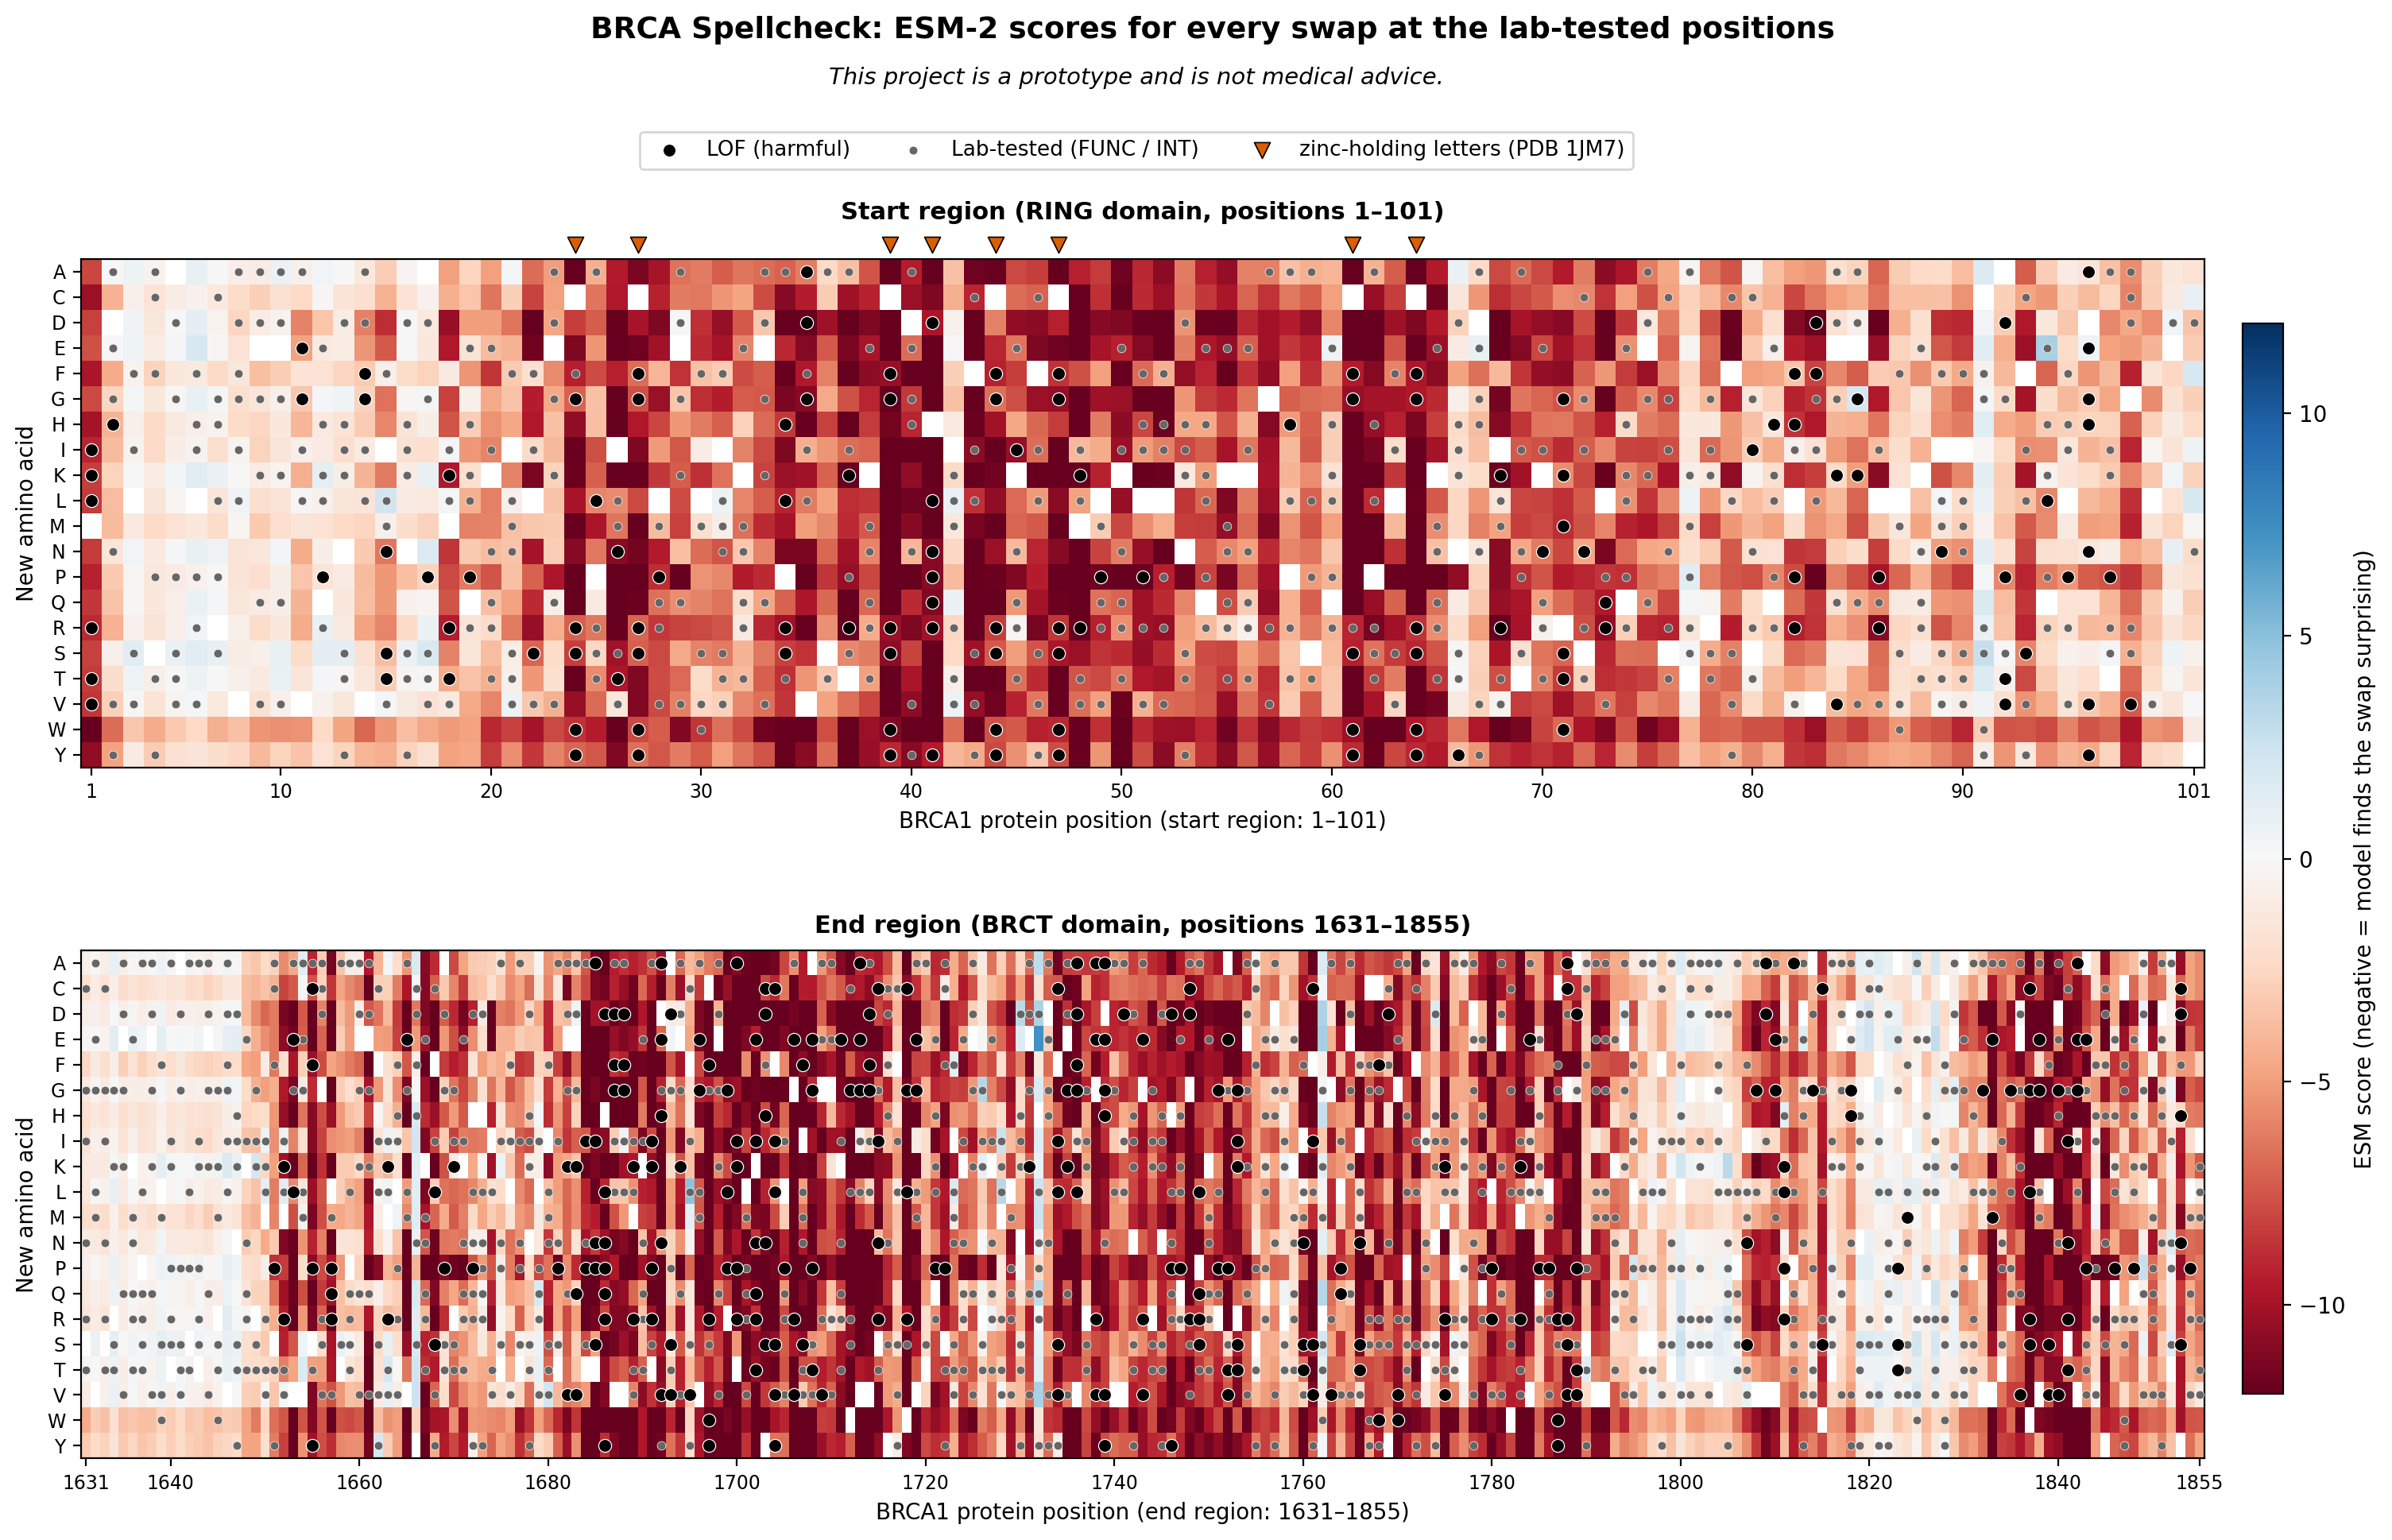

In [8]:
from IPython.display import Image, display

assert config.HEATMAP_PNG_PATH.is_file(), f"Missing {config.HEATMAP_PNG_PATH}"
display(Image(filename="outputs/heatmap.png"))

## Limitations, groups check, sources, and credits

### Limitations

**Main three limitations:**
1. **Blind to splicing (we could not test this):** The 2018 lab study edited genomic DNA (`3,893` single-nucleotide changes), so some mutations are harmful because they disrupt RNA splicing rather than because the amino-acid replacement destabilises the protein. A protein-sequence model cannot see DNA-level splicing effects, and because the supplementary DNA/RNA table is not in `data/`, we could not test this.
2. **Cells in a dish, not people:** The lab measurements track cell survival in cultured human cells, which is direct cellular evidence but indirect evidence about cancer risk in people. A 2025 follow-up preprint from the same research group reports that assay results can also depend on the cell type used.
3. **Stronger tools exist and the method is not new:** Stronger variant effect predictors exist, such as AlphaMissense (Cheng et al.), whose predictions are free to download as far as we know; we do not claim to be better or cheaper. Zero-shot masked-marginal scoring with ESM-2 on this BRCA1 table is already part of the ProteinGym benchmark, and the public Evo 2 notebook evaluates a zero-shot DNA model on the same study.

**Additional five limitations:**
4. **Small coverage:** We evaluate `326` of BRCA1's `1,863` positions (`1–101` and `1631–1855`), single-letter amino-acid substitutions only, in one gene.
5. **The model has read the BRCA1 sequence during pre-training:** `facebook/esm2_t33_650M_UR50D` saw natural BRCA1 protein sequences in UniRef50 during training (though never any lab function scores or labels).
6. **The cutoffs are our choice:** Targeting `90%` harmful catch on the `start` region (and `10%` false alarms for Cutoff B) is a design choice; a different cutoff rule changes the balance between missed harmful mutations and false alarms (`437` of `899` harmless mutations flagged by Arm 2 on the `end` region).
7. **Cross-region cutoff drift and non-transfer of supervised weights:** Cutoffs tuned on the `start` region (`1–101`) shifted when applied unchanged to the `end` region (`1631–1855`), catching `86.9%` (`232/267`) for Arm 1, `94.4%` (`252/267`) for Arm 2, and `91.8%` (`245/267`) for Arm 3 (while Arm 0 caught `0/267` with `77.1%` accuracy).
8. **Redundant where tested:** At these `326` positions, experimental lab measurements already exist (`96.5%` of all possible single-letter DNA changes measured).

### Groups check

Results are broken down across protein regions and across the `4` swap kinds in `outputs/results/by_swap.csv`:
- **By protein region:** On the `start` region (`1–101`, in-sample tuning), Arm 2 flagged `118` of `131` `LOF` mutations (`90.1%`) and `196` of `385` `FUNC` mutations (`50.9%`); on the held-out `end` region (`1631–1855`), Arm 2 caught `252` of `267` `LOF` mutations (`94.4%`) and flagged `437` of `899` `FUNC` mutations (`48.6%`). (The secondary reverse split was cut per Cut List item 2.)
- **By swap kind on the held-out `end` region (`outputs/results/by_swap.csv`):**
  - `to_proline` (`31` `LOF`, `32` `FUNC`): Arm 2 caught `29/31` (`93.5%`) with `14/32` false alarms (`43.8%`); Arm 1 caught `31/31` (`100.0%`) with `32/32` false alarms (`100.0%`); Arm 3 caught `31/31` (`100.0%`) with `25/32` false alarms (`78.1%`).
  - `loss_of_cysteine` (`9` `LOF`, `20` `FUNC`): Arm 2 caught `9/9` (`100.0%`) with `15/20` false alarms (`75.0%`); Arm 1 and Arm 3 both caught `9/9` (`100.0%`) while flagging all `20/20` harmless swaps (`100.0%` and `100.0%`).
  - `charge_change` (`96` `LOF`, `310` `FUNC`): Arm 2 caught `91/96` (`94.8%`) with `178/310` false alarms (`57.4%`), versus Arm 1 (`84/96` or `87.5%` caught, `219/310` or `70.6%` false alarms) and Arm 3 (`89/96` or `92.7%` caught, `161/310` or `51.9%` false alarms).
  - `other` (`131` `LOF`, `537` `FUNC`): Arm 2 caught `123/131` (`93.9%`) with `230/537` false alarms (`42.8%`), versus Arm 1 (`108/131` or `82.4%` caught, `300/537` or `55.9%` false alarms) and Arm 3 (`116/131` or `88.5%` caught, `199/537` or `37.1%` false alarms).

Our data are mutations, not people, so we cannot check performance by age, sex or ancestry.

### Sources and credits

### Data

- Findlay GM et al. (2018). Saturation genome editing of BRCA1 variants. *Nature* 562:217–222. https://doi.org/10.1038/s41586-018-0461-z — lab measurements and function scores (University of Washington).
- University of Washington BRCA1 saturation genome editing resource (classes and cutoffs): https://sge.gs.washington.edu/BRCA1/
- ProteinGym (Notin P et al., 2023), benchmark source of `BRCA1_HUMAN_Findlay_2018.csv`: https://github.com/OATML-Markslab/ProteinGym — also prior work, as it already evaluates ESM-2 on this table.

### Models and methods

- ESM-2 (Lin Z et al., 2023, *Science* 379:1123–1130), model `facebook/esm2_t33_650M_UR50D`: https://huggingface.co/facebook/esm2_t33_650M_UR50D and https://github.com/facebookresearch/esm
- Masked-marginal ("hide-a-letter") scoring method: Meier J et al. (2021), "Language models enable zero-shot prediction of the effects of mutations on protein function", NeurIPS. https://doi.org/10.1101/2021.07.09.450648
- BLOSUM62: Henikoff S, Henikoff JG (1992), *PNAS* 89:10915–10919, loaded via Biopython: https://biopython.org
- Kyte J, Doolittle RF (1982), *Journal of Molecular Biology* 157:105–132 — amino acid hydrophobicity scale.
- Zamyatnin AA (1972), *Progress in Biophysics and Molecular Biology* 24:107–123 — amino acid residue volumes in Å³.
- BRCA1-BARD1 RING-domain structure, RCSB Protein Data Bank entry `1JM7`: https://www.rcsb.org/structure/1JM7 — confirms RING zinc-coordinating positions 24, 27, 39, 41, 44, 47, 61, and 64.

### Prior work we do not use but must cite

- Evo 2 BRCA1 zero-shot notebook (Arc Institute; also published by NVIDIA): https://github.com/ArcInstitute/evo2 and https://docs.nvidia.com/bionemo-recipes/2.7.1/main/examples/bionemo-evo2/zeroshot_brca1/
- AlphaMissense (Cheng J et al., 2023, *Science* 381:eadg7492) — a stronger variant effect predictor, noted as a limitation and reference point.
- Follow-up preprint on cell-type context (2025): https://www.medrxiv.org/content/10.1101/2025.08.11.25333423.full.pdf

### Libraries

PyTorch, Hugging Face Transformers, NumPy, pandas, SciPy, scikit-learn, Biopython, Plotly, Matplotlib, Gradio, pytest, and Jupyter (`nbformat`, `nbconvert`, `ipykernel`).

### AI tools, with roles

- **Claude Code (Anthropic):** planning, writing the build specification, and review (running tests, auditing for test-set leakage, checking index math, checking claims in the write-up, reproducibility checks, and mock review).
- **Gemini, as a coding agent in Google Antigravity:** writing and executing the project code from the specification.

### The organisers

Veritas AI hackathon project briefs, Hacker Guide, and sample submission.

*This project is a prototype and is not medical advice.*